# Tugas - Medical Cost Prediction

Nama: Rasya Gonawi  
NRP: 5054251032

Dataset yang digunakan adalah Medical Cost Personal Dataset. Tujuan pemodelan adalah memperkirakan biaya medis (charges) dari usia, jenis kelamin, BMI, jumlah anak, status merokok, dan wilayah tempat tinggal.

Enam pendekatan yang dibandingkan adalah Linear Regression, Polynomial Regression, Ridge Regression, Lasso Regression, Decision Tree Regressor, dan Support Vector Regression.

# 1. Persiapan Dataset dan Eksplorasi Awal

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display, Markdown

from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, PolynomialFeatures, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.tree import DecisionTreeRegressor
from sklearn.svm import SVR
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

sns.set_theme(style="whitegrid")

In [2]:
df = pd.read_csv("insurance.csv")
df.shape

(1338, 7)

In [3]:
df.head()

,age,sex,bmi,children,smoker,region,charges
0,19,female,27.900,0,yes,southwest,16884.92400
1,18,male,33.770,1,no,southeast,1725.55230
2,28,male,33.000,3,no,southeast,4449.46200
3,33,male,22.705,0,no,northwest,21984.47061
4,32,male,28.880,0,no,northwest,3866.85520


In [4]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1338 entries, 0 to 1337
Data columns (total 7 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   age       1338 non-null   int64  
 1   sex       1338 non-null   object 
 2   bmi       1338 non-null   float64
 3   children  1338 non-null   int64  
 4   smoker    1338 non-null   object 
 5   region    1338 non-null   object 
 6   charges   1338 non-null   float64
dtypes: float64(2), int64(2), object(3)
memory usage: 73.3+ KB


In [5]:
df.isna().sum().to_frame("missing_values")

,missing_values
age,0
sex,0
bmi,0
children,0
smoker,0
region,0
charges,0


In [6]:
df.describe().T.round(2)

,count,mean,std,min,25%,50%,75%,max
age,1338.0,39.21,14.05,18.00,27.00,39.00,51.00,64.00
bmi,1338.0,30.66,6.10,15.96,26.30,30.40,34.69,53.13
children,1338.0,1.09,1.21,0.00,0.00,1.00,2.00,5.00
charges,1338.0,13270.42,12110.01,1121.87,4740.29,9382.03,16639.91,63770.43


In [7]:
categorical_columns = df.select_dtypes(include="object").columns.tolist()
display(pd.concat([df[col].value_counts().rename(col) for col in categorical_columns], axis=1).fillna(0).astype(int))

,sex,smoker,region
male,676,0,0
female,662,0,0
no,0,1064,0
yes,0,274,0
southeast,0,0,364
southwest,0,0,325
northwest,0,0,325
northeast,0,0,324


Exploratory Data Analysis

Perhatikan distribusi usia, BMI, dan charges, hubungan BMI dengan biaya, serta perbedaan biaya antara perokok dan bukan perokok. Grafik dan ringkasan korelasi di bawah membantu mengenali pola yang mungkin berpengaruh pada hasil regresi.

,mean,median
smoker,,
no,8434.27,7345.41
yes,32050.23,34456.35


,charges
charges,1.000
age,0.299
bmi,0.198
children,0.068


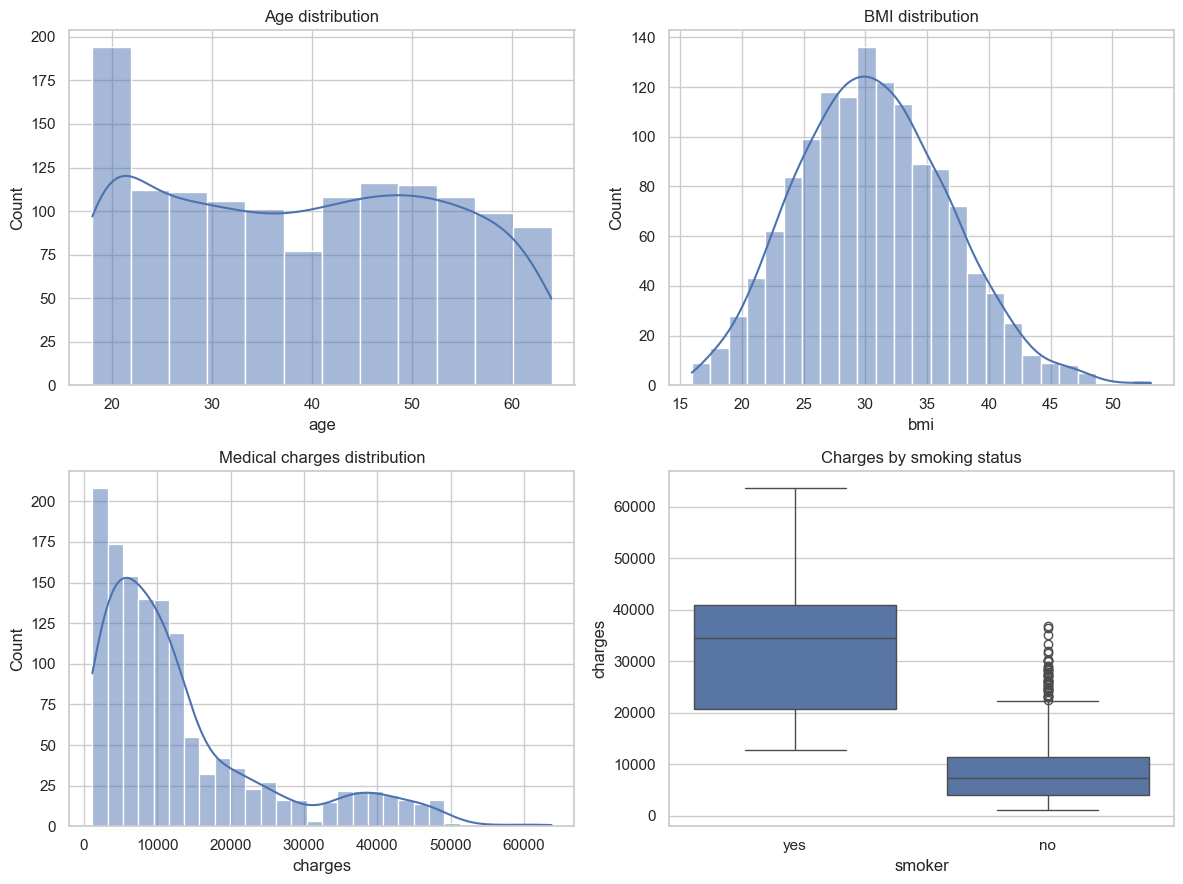

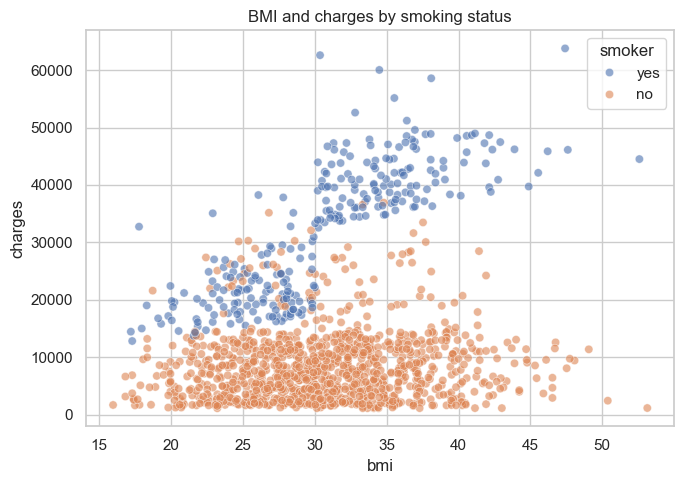

In [8]:
display(df.groupby("smoker")["charges"].agg(["mean", "median"]).round(2))
display(df.select_dtypes(include="number").corr()[["charges"]].sort_values("charges", ascending=False).round(3))

fig, axes = plt.subplots(2, 2, figsize=(12, 9))
sns.histplot(data=df, x="age", kde=True, ax=axes[0, 0])
axes[0, 0].set_title("Age distribution")
sns.histplot(data=df, x="bmi", kde=True, ax=axes[0, 1])
axes[0, 1].set_title("BMI distribution")
sns.histplot(data=df, x="charges", kde=True, ax=axes[1, 0])
axes[1, 0].set_title("Medical charges distribution")
sns.boxplot(data=df, x="smoker", y="charges", ax=axes[1, 1])
axes[1, 1].set_title("Charges by smoking status")
fig.tight_layout()
plt.show()

fig, ax = plt.subplots(figsize=(7, 5))
sns.scatterplot(data=df, x="bmi", y="charges", hue="smoker", alpha=0.6, ax=ax)
ax.set_title("BMI and charges by smoking status")
fig.tight_layout()
plt.show()

# 2. Preprocessing

Fitur numerik dan kategorikal diproses terpisah. OneHotEncoder digunakan untuk fitur kategorikal. Model linear, polynomial, Ridge, Lasso, dan SVR menggunakan fitur numerik yang distandardisasi. Decision Tree tidak memerlukan scaling. Seluruh preprocessing dipelajari dari data train melalui pipeline untuk mencegah kebocoran data.

In [9]:
X = df.drop(columns="charges")
y = df["charges"]

In [10]:
numeric_features = X.select_dtypes(include="number").columns.tolist()
categorical_features = X.select_dtypes(include="object").columns.tolist()
pd.DataFrame({"feature_type": ["numeric"] * len(numeric_features) + ["categorical"] * len(categorical_features)}, index=numeric_features + categorical_features)

,feature_type
age,numeric
bmi,numeric
children,numeric
sex,categorical
smoker,categorical
region,categorical


In [11]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)
X_train.shape, X_test.shape

((1070, 6), (268, 6))

In [12]:
scaled_preprocessor = ColumnTransformer(
    transformers=[
        ("numeric", StandardScaler(), numeric_features),
        ("categorical", OneHotEncoder(handle_unknown="ignore"), categorical_features),
    ]
)

tree_preprocessor = ColumnTransformer(
    transformers=[
        ("numeric", "passthrough", numeric_features),
        ("categorical", OneHotEncoder(handle_unknown="ignore"), categorical_features),
    ]
)

model_predictions = {}

# 3. Eksperimen Model

Linear Regression

Model ini menjadi baseline untuk melihat seberapa baik hubungan linear antara fitur dan biaya medis.

In [13]:
linear_model = Pipeline([
    ("preprocessor", scaled_preprocessor),
    ("model", LinearRegression()),
])
linear_model.fit(X_train, y_train)

,steps,"[('preprocessor', ...), ('model', ...)]"
,transform_input,None
,memory,None
,verbose,False
,transformers,"[('numeric', ...), ('categorical', ...)]"
,remainder,'drop'
,sparse_threshold,0.3
,n_jobs,None
,transformer_weights,None
,verbose,False
,verbose_feature_names_out,True


In [14]:
model_predictions["Linear Regression"] = linear_model.predict(X_test)

Polynomial Regression

PolynomialFeatures dengan degree 2 menambahkan pola kuadrat dan interaksi antarf fitur. Fitur hasil transformasi distandardisasi sebelum model dilatih.

In [15]:
polynomial_model = Pipeline([
    ("preprocessor", scaled_preprocessor),
    ("polynomial", PolynomialFeatures(degree=2, include_bias=False)),
    ("scale_polynomial", StandardScaler()),
    ("model", LinearRegression()),
])
polynomial_model.fit(X_train, y_train)

,steps,"[('preprocessor', ...), ('polynomial', ...), ...]"
,transform_input,None
,memory,None
,verbose,False
,transformers,"[('numeric', ...), ('categorical', ...)]"
,remainder,'drop'
,sparse_threshold,0.3
,n_jobs,None
,transformer_weights,None
,verbose,False
,verbose_feature_names_out,True


In [16]:
model_predictions["Polynomial Regression"] = polynomial_model.predict(X_test)

Ridge Regression

Nilai alpha dipilih dengan 5-fold cross-validation pada data train.

In [17]:
ridge_model = Pipeline([
    ("preprocessor", scaled_preprocessor),
    ("model", GridSearchCV(
        Ridge(), {"alpha": [0.1, 1, 10, 100]},
        scoring="neg_mean_squared_error", cv=5,
    )),
])
ridge_model.fit(X_train, y_train)

,steps,"[('preprocessor', ...), ('model', ...)]"
,transform_input,None
,memory,None
,verbose,False
,transformers,"[('numeric', ...), ('categorical', ...)]"
,remainder,'drop'
,sparse_threshold,0.3
,n_jobs,None
,transformer_weights,None
,verbose,False
,verbose_feature_names_out,True


In [18]:
model_predictions["Ridge Regression"] = ridge_model.predict(X_test)

Lasso Regression

Nilai alpha dipilih dengan 5-fold cross-validation. Scaling diperlukan agar penalti koefisien diterapkan secara sebanding.

In [19]:
lasso_model = Pipeline([
    ("preprocessor", scaled_preprocessor),
    ("model", GridSearchCV(
        Lasso(max_iter=20000), {"alpha": [0.001, 0.01, 0.1, 1]},
        scoring="neg_mean_squared_error", cv=5,
    )),
])
lasso_model.fit(X_train, y_train)

,steps,"[('preprocessor', ...), ('model', ...)]"
,transform_input,None
,memory,None
,verbose,False
,transformers,"[('numeric', ...), ('categorical', ...)]"
,remainder,'drop'
,sparse_threshold,0.3
,n_jobs,None
,transformer_weights,None
,verbose,False
,verbose_feature_names_out,True


In [20]:
model_predictions["Lasso Regression"] = lasso_model.predict(X_test)

Decision Tree Regressor

Kedalaman maksimum dan jumlah minimum sampel pada daun dipilih dengan 5-fold cross-validation. Fitur numerik tidak distandardisasi.

In [21]:
tree_model = Pipeline([
    ("preprocessor", tree_preprocessor),
    ("model", GridSearchCV(
        DecisionTreeRegressor(random_state=42),
        {"max_depth": [3, 5, 8, None], "min_samples_leaf": [1, 5]},
        scoring="neg_mean_squared_error", cv=5,
    )),
])
tree_model.fit(X_train, y_train)

,steps,"[('preprocessor', ...), ('model', ...)]"
,transform_input,None
,memory,None
,verbose,False
,transformers,"[('numeric', ...), ('categorical', ...)]"
,remainder,'drop'
,sparse_threshold,0.3
,n_jobs,None
,transformer_weights,None
,verbose,False
,verbose_feature_names_out,True


In [22]:
model_predictions["Decision Tree Regressor"] = tree_model.predict(X_test)

Support Vector Regression

SVR memakai kernel RBF dan data yang distandardisasi. Parameter C dan epsilon dipilih dengan 5-fold cross-validation.

In [23]:
svr_model = Pipeline([
    ("preprocessor", scaled_preprocessor),
    ("model", GridSearchCV(
        SVR(kernel="rbf"),
        {"C": [1, 10, 100], "epsilon": [0.1, 1]},
        scoring="neg_mean_squared_error", cv=5,
    )),
])
svr_model.fit(X_train, y_train)

,steps,"[('preprocessor', ...), ('model', ...)]"
,transform_input,None
,memory,None
,verbose,False
,transformers,"[('numeric', ...), ('categorical', ...)]"
,remainder,'drop'
,sparse_threshold,0.3
,n_jobs,None
,transformer_weights,None
,verbose,False
,verbose_feature_names_out,True


In [24]:
model_predictions["Support Vector Regression"] = svr_model.predict(X_test)

# 4. Evaluasi Model

In [25]:
metrics = {
    name: {
        "MAE": mean_absolute_error(y_test, prediction),
        "MSE": mean_squared_error(y_test, prediction),
        "RMSE": np.sqrt(mean_squared_error(y_test, prediction)),
        "R2": r2_score(y_test, prediction),
    }
    for name, prediction in model_predictions.items()
}
results = pd.DataFrame.from_dict(metrics, orient="index").sort_values("RMSE")
display(results.round(2))

best_parameters = {
    "Linear Regression": {"fit_intercept": True},
    "Polynomial Regression": {"degree": 2},
    "Ridge Regression": ridge_model.named_steps["model"].best_params_,
    "Lasso Regression": lasso_model.named_steps["model"].best_params_,
    "Decision Tree Regressor": tree_model.named_steps["model"].best_params_,
    "Support Vector Regression": svr_model.named_steps["model"].best_params_,
}
display(pd.DataFrame({"Model": best_parameters.keys(), "Parameter terpilih": best_parameters.values()}))

,MAE,MSE,RMSE,R2
Polynomial Regression,2729.50,2.071281e+07,4551.13,0.87
Decision Tree Regressor,2865.64,2.281267e+07,4776.26,0.85
Linear Regression,4181.19,3.359692e+07,5796.28,0.78
Lasso Regression,4182.08,3.360584e+07,5797.05,0.78
Ridge Regression,4186.91,3.362027e+07,5798.30,0.78
Support Vector Regression,5967.64,1.339914e+08,11575.47,0.14


,Model,Parameter terpilih
0,Linear Regression,{'fit_intercept': True}
1,Polynomial Regression,{'degree': 2}
2,Ridge Regression,{'alpha': 1}
3,Lasso Regression,{'alpha': 1}
4,Decision Tree Regressor,"{'max_depth': 3, 'min_samples_leaf': 1}"
5,Support Vector Regression,"{'C': 100, 'epsilon': 1}"


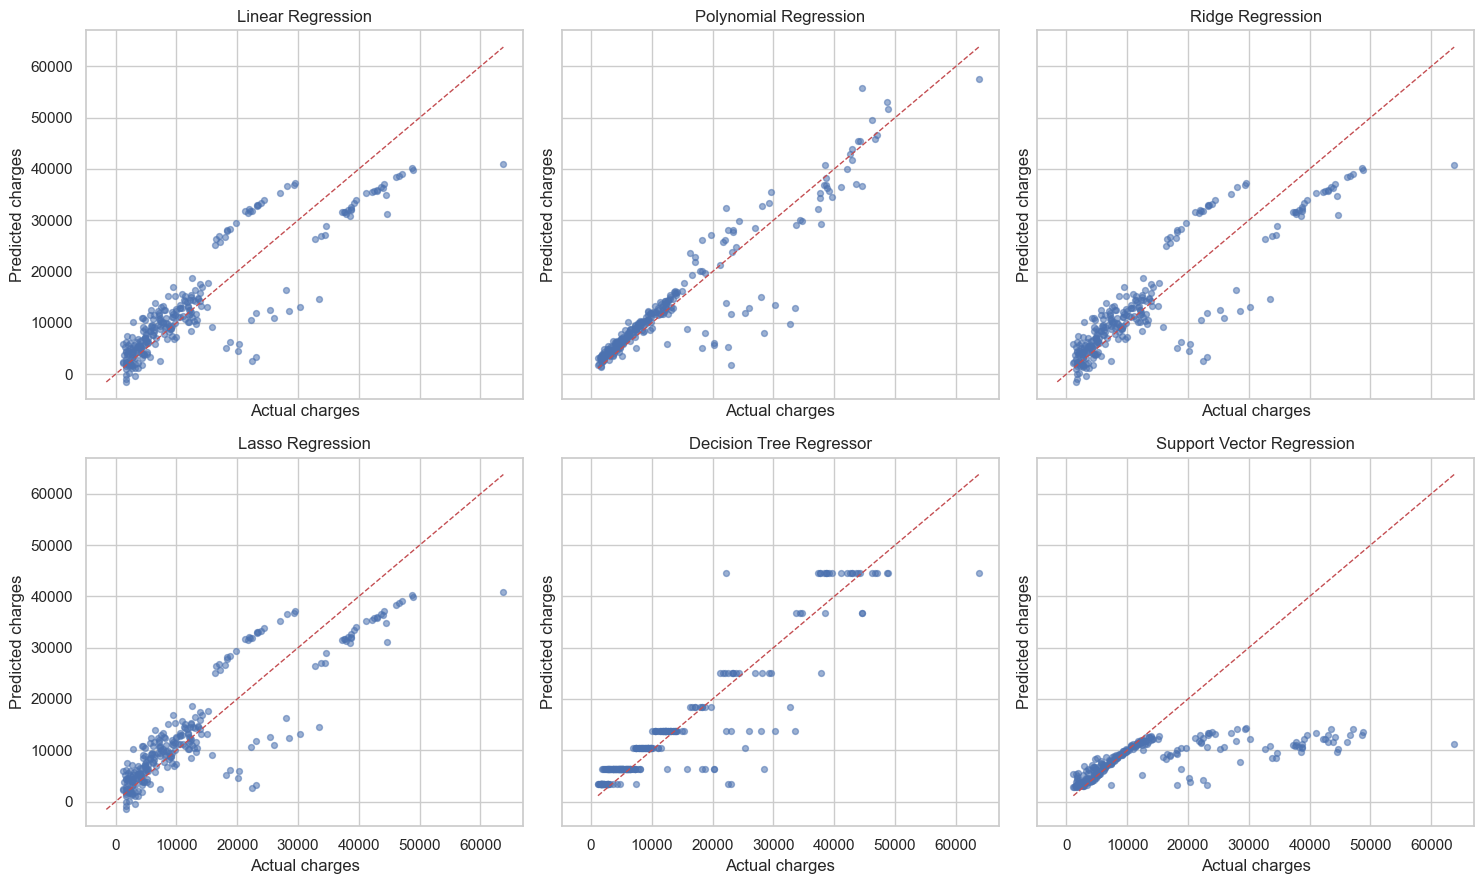

In [26]:
fig, axes = plt.subplots(2, 3, figsize=(15, 9), sharex=True, sharey=True)

for ax, (name, prediction) in zip(axes.flat, model_predictions.items()):
    ax.scatter(y_test, prediction, alpha=0.55, s=18)
    limits = [min(y_test.min(), prediction.min()), max(y_test.max(), prediction.max())]
    ax.plot(limits, limits, "r--", linewidth=1)
    ax.set_title(name)
    ax.set_xlabel("Actual charges")
    ax.set_ylabel("Predicted charges")

fig.tight_layout()
plt.show()

Analisis

Polynomial Regression memberikan hasil terbaik pada test set, dengan MAE 2,729.50, RMSE 4,551.13, dan R2 0.867. Dibanding Linear Regression, RMSE-nya sekitar 21.5% lebih rendah. Suku kuadrat dan interaksi pada degree 2 tampaknya membantu menangkap hubungan yang tidak cukup dijelaskan oleh garis lurus. Karena modelnya lebih fleksibel, hasil ini tetap perlu diuji pada pembagian data lain.

Decision Tree berada di urutan kedua dengan MAE 2,865.64, RMSE 4,776.26, dan R2 0.853. Hasilnya cukup dekat dengan Polynomial Regression. Pohon dapat membagi data berdasarkan ambang fitur dan menangkap pola non-linear tanpa scaling; batas kedalaman tiga membantu menahan kompleksitasnya.

Linear Regression memperoleh MAE 4,181.19, RMSE 5,796.28, dan R2 0.784. Sebagai model baseline, hasilnya cukup baik, tetapi selisih dengan dua model teratas menunjukkan bahwa hubungan fitur dengan charges tidak seluruhnya linear.

Ridge Regression menghasilkan MAE 4,186.91, RMSE 5,798.30, dan R2 0.783. Angkanya nyaris sama dengan Linear Regression. Pada eksperimen ini, regularisasi dengan alpha 1 tidak memberi peningkatan berarti.

Lasso Regression memperoleh MAE 4,182.08, RMSE 5,797.05, dan R2 0.784. Hasilnya juga hampir sama dengan model linear biasa. Alpha 1 tidak membuat seleksi koefisien menghasilkan perbaikan yang terlihat pada test set.

Support Vector Regression memberikan hasil terendah di antara model yang diuji: MAE 5,967.64, RMSE 11,575.47, dan R2 0.137. Artinya, pada konfigurasi dan rentang parameter ini, prediksinya jauh lebih buruk daripada lima model lain. Scaling sudah diterapkan, tetapi hasilnya menunjukkan bahwa pencarian parameter yang lebih luas atau penanganan nilai charges yang ekstrem mungkin perlu dicoba sebelum SVR dinilai lebih lanjut.

Ridge dan Lasso dipilih dengan cross-validation, demikian pula parameter untuk Decision Tree dan SVR. Semua metrik akhir dihitung pada test set yang sama, sehingga perbandingannya adil untuk pembagian data ini.

Analisis

Polynomial Regression memberikan hasil terbaik pada data uji. Model ini memperoleh MAE 2.729,50, RMSE 4.551,13, dan R2 0,867. RMSE-nya sekitar 21,5% lebih rendah daripada Linear Regression. Suku kuadrat pada degree 2 membantu model menangkap hubungan dan interaksi yang tidak tertangkap oleh garis lurus. Namun, karena modelnya lebih fleksibel, hasilnya tetap perlu diperiksa pada pembagian data lain.

Decision Tree Regressor menempati urutan kedua dengan MAE 2.865,64, RMSE 4.776,26, dan R2 0,853. Hasilnya cukup dekat dengan Polynomial Regression. Pohon dapat menangkap pola non-linear melalui pemisahan fitur dan tidak membutuhkan scaling. Kedalaman maksimum 3 membatasi kompleksitas pohon pada eksperimen ini.

Linear Regression memperoleh MAE 4.181,19, RMSE 5.796,28, dan R2 0,784. Sebagai baseline, model ini cukup baik, tetapi hasilnya menunjukkan hubungan antara fitur dan biaya medis tidak sepenuhnya linear.

Lasso Regression menghasilkan MAE 4.182,08, RMSE 5.797,05, dan R2 0,784. Ridge Regression memperoleh MAE 4.186,91, RMSE 5.798,30, dan R2 0,783. Performa keduanya hampir sama dengan Linear Regression. Pada nilai alpha yang dipilih melalui cross-validation, regularisasi belum memberikan peningkatan berarti pada data uji.

Support Vector Regression memperoleh MAE 5.967,64, RMSE 11.575,47, dan R2 0,137. Walaupun fitur sudah distandardisasi, performanya paling rendah di antara model yang dibandingkan. Rentang parameter C dan epsilon yang diuji mungkin belum sesuai dengan pola data ini, sehingga SVR masih memerlukan penyetelan lebih lanjut.

Seluruh model dinilai pada test set yang sama. Parameter Ridge, Lasso, Decision Tree, dan SVR dipilih melalui 5-fold cross-validation pada data train, sehingga data uji tidak digunakan dalam pemilihan parameter.

Kesimpulan dan saran

Untuk pembagian data ini, Polynomial Regression menjadi pilihan terbaik karena memberi MAE dan RMSE terendah serta R2 tertinggi. Decision Tree juga menunjukkan performa yang kuat dan cukup dekat, sementara Linear Regression, Ridge, dan Lasso memberikan hasil yang hampir sama. SVR belum cocok dengan rentang parameter yang dicoba.

Hasil ini belum cukup untuk menyatakan model akan selalu unggul pada data lain. Langkah berikutnya adalah mengulang evaluasi dengan beberapa pembagian data, memeriksa residual, dan mencoba transformasi log pada charges yang distribusinya menceng serta memiliki nilai ekstrem. Semua pemilihan parameter tetap dilakukan hanya pada data train agar test set tidak ikut memengaruhi model.